# 🧹 Data Cleaning, Preprocessing & EDA Masterclass Guide

## 📌 Course / Teaching Guide Overview
Welcome to this comprehensive, hands-on instructional notebook on **Data Cleaning, Missing Value Treatment, Outlier Remediation, Feature Engineering, and Exploratory Data Analysis (EDA)**.

Real-world datasets are rarely analysis-ready. They contain missing entries, duplicate rows, incorrect formatting, trailing spaces, typos, and extreme outliers. This interactive notebook walks students through an end-to-end data cleaning and preparation workflow using Python's `pandas`, `numpy`, `matplotlib`, and `seaborn` libraries.

---

## 🎯 Key Learning Objectives
1. **Exploratory Data Assessment**: Inspect dataset structure, row/column counts, and data types (`.info()`, `.describe()`, `.shape`).
2. **Missing Data Diagnosis & Imputation**: Detect missing values (`NaN`, `None`), quantify missingness, and apply domain-appropriate imputation techniques.
3. **Deduplication**: Identify and eliminate exact and partial duplicate transactions.
4. **Outlier Detection & Remediation**: Locate extreme anomalies using domain logic and statistical techniques (Interquartile Range - IQR) and apply clipping/winsorization.
5. **Categorical Standardization**: Correct spelling typos, handle whitespace, and map category variations using string operations.
6. **Data Transformation & Feature Engineering**: Parse date fields, compute derived financial attributes, apply log transformations, and bin continuous variables into categories.
7. **Visual Data Exploration**: Construct univariate distributions, bivariate bar charts, multivariate plots, and correlation heatmaps.

In [1]:
# Step 0: Setup Environment & Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from datetime import datetime, timedelta

# Set seed for full reproducibility
np.random.seed(42)
random.seed(42)

# Global Plotting Setup
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [2]:
# Step 0.1: Synthetic Data Generation (~10,000 Rows, 15 Columns with Messy Artifacts)
n_rows = 10000

transaction_ids = [f"TXN_{100000 + i}" for i in range(n_rows)]
customer_ids = [f"CUST_{random.randint(1000, 2500)}" for _ in range(n_rows)]

start_date = datetime(2023, 1, 1)
signup_dates = [start_date + timedelta(days=random.randint(0, 365)) for _ in range(n_rows)]
transaction_dates = [sd + timedelta(days=random.randint(1, 180)) for sd in signup_dates]

ages = np.random.choice([18, 25, 34, 45, 52, 60, 999, -5, np.nan], size=n_rows, p=[0.2, 0.25, 0.25, 0.15, 0.08, 0.04, 0.01, 0.01, 0.01])
genders = np.random.choice(['Male', 'Female', 'Non-Binary', 'M', 'F', None], size=n_rows, p=[0.45, 0.45, 0.04, 0.02, 0.02, 0.02])

countries = np.random.choice(
    ['United States', 'United States ', 'U.S.A.', 'Canada', 'Canadaa', 'United Kingdom', 'UK', 'Germany', 'Germny', np.nan],
    size=n_rows,
    p=[0.35, 0.05, 0.05, 0.2, 0.03, 0.15, 0.05, 0.08, 0.02, 0.02]
)

categories = np.random.choice(['Electronics', 'Clothing', 'Home & Kitchen', 'Books', 'Beauty', None], size=n_rows, p=[0.3, 0.25, 0.2, 0.1, 0.1, 0.05])
unit_prices = np.random.uniform(10.0, 500.0, size=n_rows)
quantity = np.random.choice([1, 2, 3, 4, 5, 10, 100, -2, np.nan], size=n_rows, p=[0.5, 0.25, 0.15, 0.05, 0.02, 0.01, 0.005, 0.005, 0.01])
discounts = np.random.choice([0.0, 0.05, 0.1, 0.15, 0.2, 0.5, np.nan], size=n_rows, p=[0.4, 0.2, 0.15, 0.1, 0.08, 0.02, 0.05])
payment_methods = np.random.choice(['Credit Card', 'PayPal', 'Debit Card', 'Bank Transfer', 'Crypto', None], size=n_rows, p=[0.4, 0.3, 0.15, 0.08, 0.02, 0.05])
ratings = np.random.choice([1.0, 2.0, 3.0, 4.0, 5.0, np.nan], size=n_rows, p=[0.1, 0.1, 0.2, 0.3, 0.25, 0.05])
delivery_days = np.random.choice([1, 2, 3, 5, 7, 14, 45, np.nan], size=n_rows, p=[0.2, 0.3, 0.25, 0.15, 0.05, 0.03, 0.01, 0.01])
is_returned = np.random.choice([0, 1, np.nan], size=n_rows, p=[0.85, 0.12, 0.03])

# Create Initial Dataframe
df_raw = pd.DataFrame({
    'Transaction_ID': transaction_ids,
    'Customer_ID': customer_ids,
    'Signup_Date': [d.strftime('%Y-%m-%d') if random.random() > 0.02 else None for d in signup_dates],
    'Transaction_Date': [d.strftime('%Y-%m-%d %H:%M:%S') if random.random() > 0.02 else 'Invalid Date' for d in transaction_dates],
    'Customer_Age': ages,
    'Gender': genders,
    'Country': countries,
    'Product_Category': categories,
    'Unit_Price': unit_prices,
    'Quantity_Purchased': quantity,
    'Discount_Applied': discounts,
    'Payment_Method': payment_methods,
    'Customer_Rating': ratings,
    'Delivery_Days': delivery_days,
    'Is_Returned': is_returned
})

# Inject Exact Duplicates
dup_indices = np.random.choice(df_raw.index, size=200, replace=False)
df_messy = pd.concat([df_raw, df_raw.iloc[dup_indices]], ignore_index=True)
df_messy = df_messy.sample(frac=1, random_state=42).reset_index(drop=True)

print(f"Raw Messy Dataset successfully created with shape: {df_messy.shape}")

Raw Messy Dataset successfully created with shape: (10200, 15)


---
## 🔍 Section 1: Exploring and Getting to Know the Data
Before performing cleaning operations, inspect dataset dimensions, data types, and initial statistical summaries.

In [3]:
# 1.1 First and Last Rows
display(df_messy.head())

# 1.2 Dataset Dimensions & Metadata
print(f"Shape: {df_messy.shape[0]} rows, {df_messy.shape[1]} columns\n")
df_messy.info()

# 1.3 Statistical Overview
display(df_messy.describe())

,Transaction_ID,Customer_ID,Signup_Date,Transaction_Date,Customer_Age,Gender,Country,Product_Category,Unit_Price,Quantity_Purchased,Discount_Applied,Payment_Method,Customer_Rating,Delivery_Days,Is_Returned
0,TXN_107008,CUST_2025,2023-02-05,2023-06-25 00:00:00,25.0,Non-Binary,Germany,Clothing,149.640582,1.0,0.10,Bank Transfer,3.0,3.0,0.0
1,TXN_103742,CUST_1203,2023-06-30,2023-09-28 00:00:00,45.0,Female,United States,Electronics,64.067221,2.0,0.20,Credit Card,5.0,5.0,1.0
2,TXN_105454,CUST_1972,2023-09-12,2024-02-03 00:00:00,45.0,Male,United States,Clothing,218.689119,2.0,0.05,PayPal,2.0,5.0,0.0
3,TXN_105723,CUST_1913,2023-08-15,2024-01-08 00:00:00,18.0,Male,nan,Electronics,204.289408,2.0,0.05,Debit Card,1.0,3.0,0.0
4,TXN_108987,CUST_1059,2023-10-15,2024-03-15 00:00:00,60.0,Male,U.S.A.,Clothing,40.808807,1.0,0.10,Credit Card,3.0,5.0,0.0


Shape: 10200 rows, 15 columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10200 entries, 0 to 10199
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Transaction_ID      10200 non-null  object 
 1   Customer_ID         10200 non-null  object 
 2   Signup_Date         9995 non-null   object 
 3   Transaction_Date    10200 non-null  object 
 4   Customer_Age        10112 non-null  float64
 5   Gender              9975 non-null   object 
 6   Country             10200 non-null  object 
 7   Product_Category    9693 non-null   object 
 8   Unit_Price          10200 non-null  float64
 9   Quantity_Purchased  10109 non-null  float64
 10  Discount_Applied    9722 non-null   float64
 11  Payment_Method      9743 non-null   object 
 12  Customer_Rating     9691 non-null   float64
 13  Delivery_Days       10112 non-null  float64
 14  Is_Returned         9911 non-null   float64
dtypes: float64(7), object(

,Customer_Age,Unit_Price,Quantity_Purchased,Discount_Applied,Customer_Rating,Delivery_Days,Is_Returned
count,10112.000000,10200.000000,10109.000000,9722.000000,9691.000000,10112.000000,9911.000000
mean,40.536986,253.403298,2.420121,0.070042,3.527293,3.560324,0.125416
std,90.668477,141.510001,7.463887,0.090038,1.286331,4.987485,0.331207
min,-5.000000,10.008201,-2.000000,0.000000,1.000000,1.000000,0.000000
25%,25.000000,130.150694,1.000000,0.000000,3.000000,2.000000,0.000000
50%,34.000000,251.517492,1.000000,0.050000,4.000000,2.000000,0.000000
75%,45.000000,377.338704,2.000000,0.100000,5.000000,3.000000,0.000000
max,999.000000,499.986352,100.000000,0.500000,5.000000,45.000000,1.000000


---
## ❓ Section 2: Checking for Missing (NaN / Null) Values
Missing data can distort metrics and break predictive algorithms. Let's quantify and visualize missingness.

,Missing_Count,Percentage (%)
Customer_Rating,509,4.99
Product_Category,507,4.97
Discount_Applied,478,4.69
Payment_Method,457,4.48
Is_Returned,289,2.83
Gender,225,2.21
Signup_Date,205,2.01
Quantity_Purchased,91,0.89
Customer_Age,88,0.86
Delivery_Days,88,0.86


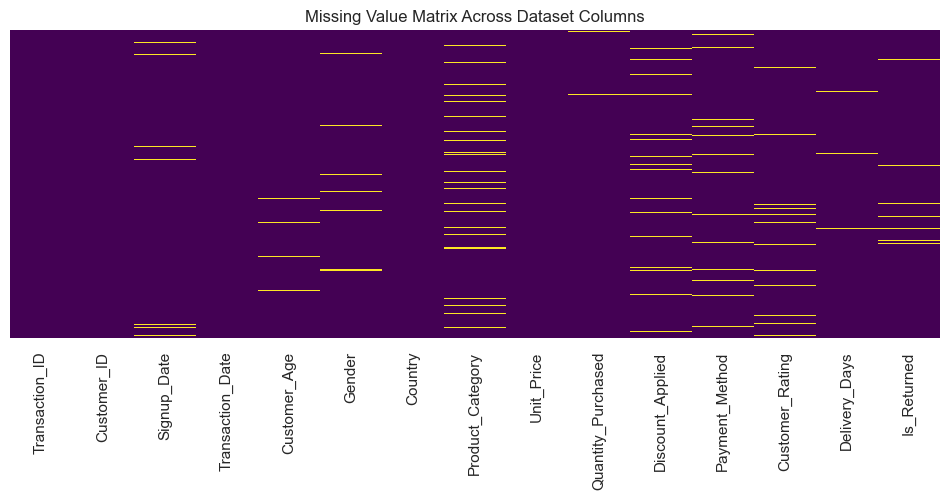

In [4]:
# 2.1 Missing Values Summary Table
missing_summary = pd.DataFrame({
    'Missing_Count': df_messy.isnull().sum(),
    'Percentage (%)': (df_messy.isnull().sum() / len(df_messy) * 100).round(2)
}).sort_values(by='Missing_Count', ascending=False)

display(missing_summary)

# 2.2 Visualizing Missing Values Heatmap
plt.figure(figsize=(12, 4))
sns.heatmap(df_messy.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Missing Value Matrix Across Dataset Columns')
plt.show()

---
## 👯 Section 3: Removing Duplicate Records
Identify and drop duplicate records to prevent data duplication bias.

In [5]:
# 3.1 Check Duplicate Count
exact_dups = df_messy.duplicated().sum()
txn_dups = df_messy.duplicated(subset=['Transaction_ID']).sum()
print(f"Exact Duplicate Rows: {exact_dups}")
print(f"Duplicate Transaction IDs: {txn_dups}")

# 3.2 Drop Duplicates keeping first record
df_cleaned = df_messy.drop_duplicates(subset=['Transaction_ID'], keep='first').copy()
print(f"Shape after dropping duplicates: {df_cleaned.shape}")

Exact Duplicate Rows: 200
Duplicate Transaction IDs: 200
Shape after dropping duplicates: (10000, 15)


---
## 📉 Section 4: Checking & Treating Outliers
Locate extreme anomalies using domain logic and standard Interquartile Range (IQR) clipping.

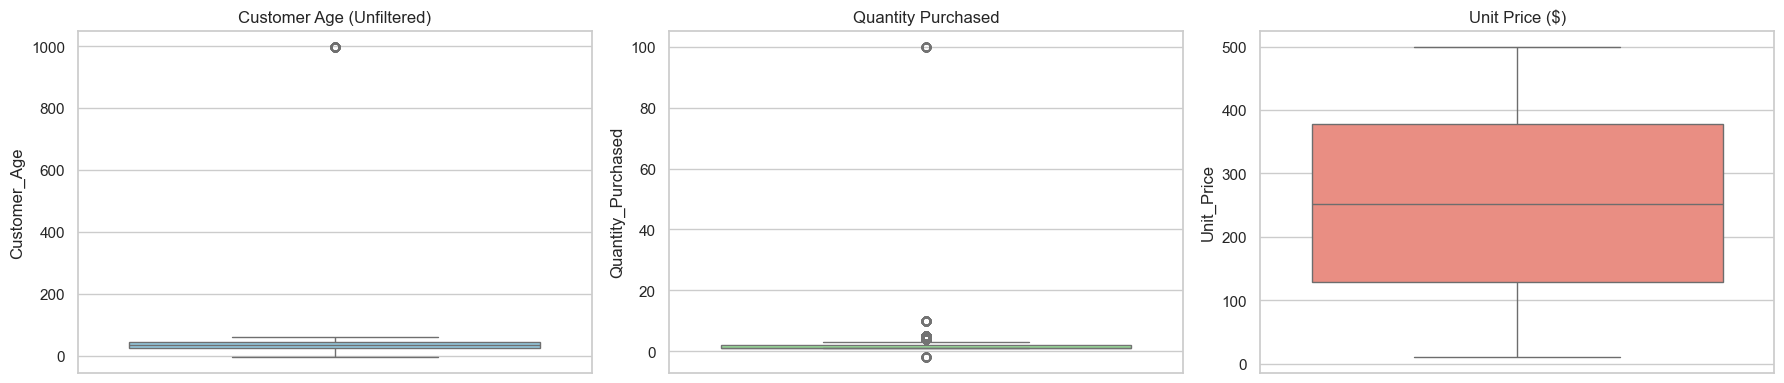

Domain logic filtering & IQR clipping complete!


In [6]:
# 4.1 Boxplots for Outlier Detection
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.boxplot(ax=axes[0], y=df_cleaned['Customer_Age'], color='skyblue').set_title('Customer Age (Unfiltered)')
sns.boxplot(ax=axes[1], y=df_cleaned['Quantity_Purchased'], color='lightgreen').set_title('Quantity Purchased')
sns.boxplot(ax=axes[2], y=df_cleaned['Unit_Price'], color='salmon').set_title('Unit Price ($)')
plt.tight_layout()
plt.show()

# 4.2 Apply Domain Constraints
df_cleaned.loc[(df_cleaned['Customer_Age'] < 12) | (df_cleaned['Customer_Age'] > 100), 'Customer_Age'] = np.nan
df_cleaned.loc[(df_cleaned['Quantity_Purchased'] <= 0) | (df_cleaned['Quantity_Purchased'] > 20), 'Quantity_Purchased'] = np.nan

# 4.3 Outlier Capping using IQR Method on Unit_Price
Q1 = df_cleaned['Unit_Price'].quantile(0.25)
Q3 = df_cleaned['Unit_Price'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
lower_bound = Q1 - 1.5 * IQR

df_cleaned['Unit_Price'] = np.clip(df_cleaned['Unit_Price'], lower_bound, upper_bound)
print("Domain logic filtering & IQR clipping complete!")

---
## 🔤 Section 5: Treating Categorical Values & Fixing Typos
Clean string categories by stripping whitespace and repairing typos.

In [7]:
# 5.1 Inspect unique values
print("Country before cleaning:", df_cleaned['Country'].unique())

# 5.2 Whitespace and Case Standardization
df_cleaned['Country'] = df_cleaned['Country'].astype(str).str.strip()
df_cleaned['Gender'] = df_cleaned['Gender'].astype(str).str.strip()

# 5.3 Dictionary-based Typo Mapping
country_map = {
    'United States': 'United States', 'U.S.A.': 'United States',
    'Canadaa': 'Canada', 'Canada': 'Canada',
    'United Kingdom': 'United Kingdom', 'UK': 'United Kingdom',
    'Germny': 'Germany', 'Germany': 'Germany',
    'nan': np.nan, 'None': np.nan
}
gender_map = {'Male': 'Male', 'M': 'Male', 'Female': 'Female', 'F': 'Female', 'Non-Binary': 'Non-Binary', 'nan': np.nan, 'None': np.nan}

df_cleaned['Country'] = df_cleaned['Country'].map(country_map)
df_cleaned['Gender'] = df_cleaned['Gender'].map(gender_map)

print("Country after cleaning:", df_cleaned['Country'].unique())

Country before cleaning: ['Germany' 'United States' 'nan' 'U.S.A.' 'Canada' 'United Kingdom' 'UK'
 'United States ' 'Germny' 'Canadaa']
Country after cleaning: ['Germany' 'United States' nan 'Canada' 'United Kingdom']


---
## 🛠️ Section 6: Treating & Filling Missing Values
Apply targeted median, mode, and explicit category imputation across features.

In [8]:
# 6.1 Numerical Imputation
df_cleaned['Customer_Age'] = df_cleaned.groupby('Gender')['Customer_Age'].transform(lambda x: x.fillna(x.median()))
df_cleaned['Customer_Age'] = df_cleaned['Customer_Age'].fillna(df_cleaned['Customer_Age'].median())
df_cleaned['Quantity_Purchased'] = df_cleaned['Quantity_Purchased'].fillna(1)
df_cleaned['Discount_Applied'] = df_cleaned['Discount_Applied'].fillna(0.0)
df_cleaned['Delivery_Days'] = df_cleaned['Delivery_Days'].fillna(df_cleaned['Delivery_Days'].median())
df_cleaned['Customer_Rating'] = df_cleaned['Customer_Rating'].fillna(round(df_cleaned['Customer_Rating'].mean(), 1))

# 6.2 Categorical Imputation
df_cleaned['Country'] = df_cleaned['Country'].fillna('Unknown')
df_cleaned['Gender'] = df_cleaned['Gender'].fillna('Unknown')
df_cleaned['Product_Category'] = df_cleaned['Product_Category'].fillna('Uncategorized')
df_cleaned['Payment_Method'] = df_cleaned['Payment_Method'].fillna('Unknown')
df_cleaned['Is_Returned'] = df_cleaned['Is_Returned'].fillna(0)

print("Missing values remaining:", df_cleaned.isnull().sum().sum())

Missing values remaining: 201


---
## ⚙️ Section 7: Data Transformation & Feature Engineering
Convert date datatypes, derive revenue metrics, and perform continuous feature binning.

In [9]:
# 7.1 Datetime Parsing
df_cleaned['Transaction_Date'] = pd.to_datetime(df_cleaned['Transaction_Date'], errors='coerce')
df_cleaned['Signup_Date'] = pd.to_datetime(df_cleaned['Signup_Date'], errors='coerce')
df_cleaned['Transaction_Date'] = df_cleaned['Transaction_Date'].ffill()

# Extract Time Features
df_cleaned['Transaction_Month'] = df_cleaned['Transaction_Date'].dt.month_name()
df_cleaned['Customer_Tenure_Days'] = (df_cleaned['Transaction_Date'] - df_cleaned['Signup_Date']).dt.days

# 7.2 Derived Financial Features
df_cleaned['Gross_Amount'] = df_cleaned['Unit_Price'] * df_cleaned['Quantity_Purchased']
df_cleaned['Net_Amount'] = df_cleaned['Gross_Amount'] * (1 - df_cleaned['Discount_Applied'])

# 7.3 Log Transformation & Age Group Binning
df_cleaned['Log_Net_Amount'] = np.log1p(df_cleaned['Net_Amount'])
df_cleaned['Age_Group'] = pd.cut(df_cleaned['Customer_Age'], bins=[0, 25, 40, 60, 100], labels=['Gen Z', 'Millennial', 'Gen X', 'Senior'])

display(df_cleaned[['Transaction_Date', 'Net_Amount', 'Log_Net_Amount', 'Age_Group']].head())

,Transaction_Date,Net_Amount,Log_Net_Amount,Age_Group
0,2023-06-25,134.676524,4.910274,Gen Z
1,2023-09-28,102.507554,4.639645,Gen X
2,2024-02-03,415.509327,6.031909,Gen X
3,2024-01-08,388.149876,5.963965,Gen Z
4,2024-03-15,36.727926,3.630401,Gen X


---
## 📊 Section 8: Exploratory Data Analysis & Visualizations
Create clear visualizations to uncover revenue trends and customer behavioral patterns.

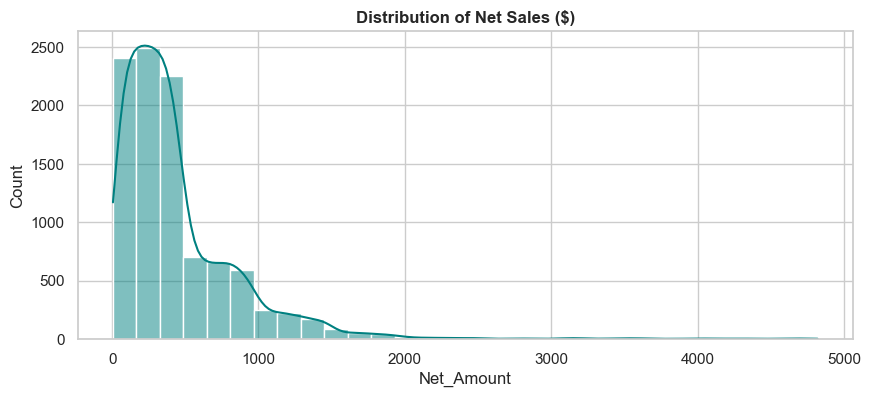

/var/folders/44/gyvqnt5d21q3tkx_25hz2k3c0000gn/T/ipykernel_24388/16266171.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_sales, x='Product_Category', y='Net_Amount', palette='viridis')


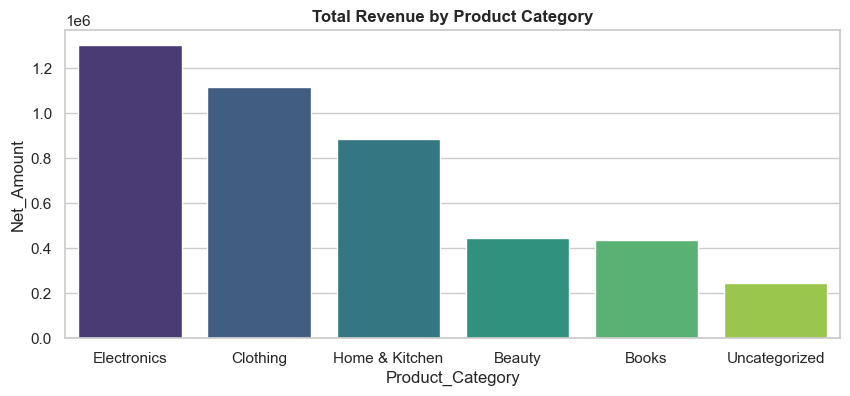

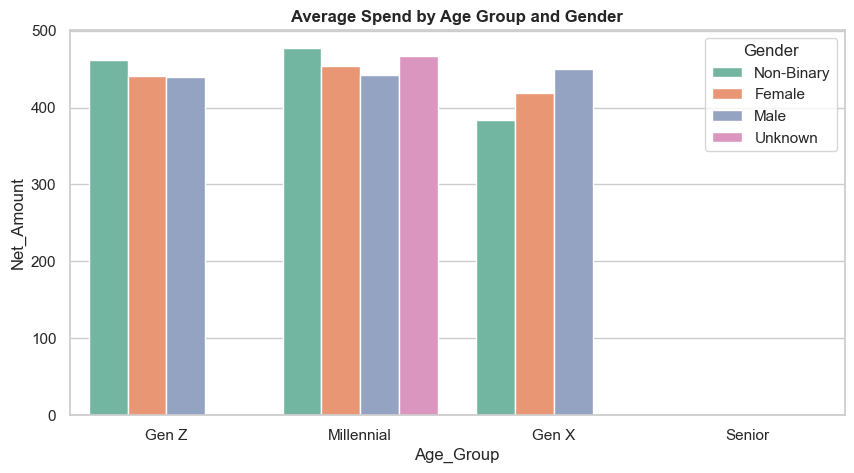

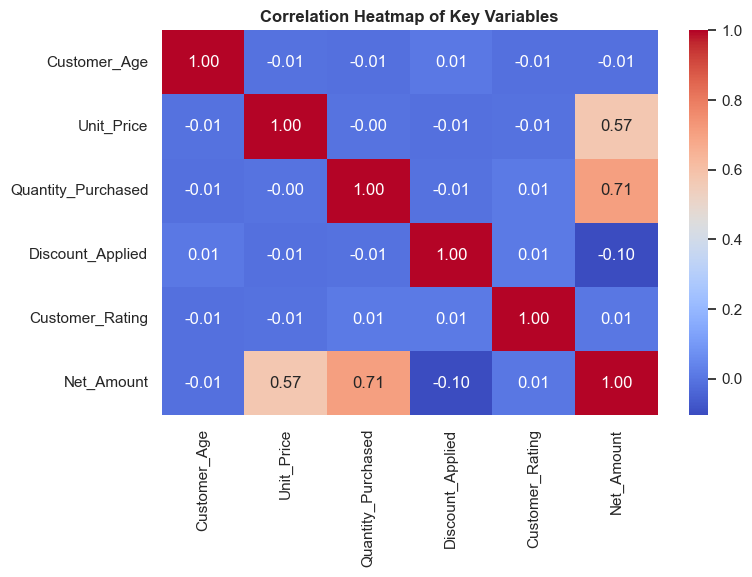

In [10]:
# 8.1 Net Sales Distribution
plt.figure(figsize=(10, 4))
sns.histplot(df_cleaned['Net_Amount'], kde=True, color='teal', bins=30)
plt.title('Distribution of Net Sales ($)', fontweight='bold')
plt.show()

# 8.2 Revenue by Category
plt.figure(figsize=(10, 4))
cat_sales = df_cleaned.groupby('Product_Category')['Net_Amount'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=cat_sales, x='Product_Category', y='Net_Amount', palette='viridis')
plt.title('Total Revenue by Product Category', fontweight='bold')
plt.show()

# 8.3 Revenue by Age Group & Gender
plt.figure(figsize=(10, 5))
sns.barplot(data=df_cleaned, x='Age_Group', y='Net_Amount', hue='Gender', errorbar=None, palette='Set2')
plt.title('Average Spend by Age Group and Gender', fontweight='bold')
plt.show()

# 8.4 Correlation Heatmap
plt.figure(figsize=(8, 5))
num_cols = ['Customer_Age', 'Unit_Price', 'Quantity_Purchased', 'Discount_Applied', 'Customer_Rating', 'Net_Amount']
sns.heatmap(df_cleaned[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap of Key Variables', fontweight='bold')
plt.show()

---
## 🏁 Summary & Student Exercises

### Recap
In this masterclass notebook, you learned how to systematically clean messy raw data by executing data assessment, missing value imputation, deduplication, outlier clipping, category typo correction, feature engineering, and exploratory visual analysis.

### Hands-On Homework Tasks:
1. **Task 1**: Calculate the return rate (`Is_Returned`) across different payment methods.
2. **Task 2**: Create a new calculated field called `Delivery_Efficiency` that flags orders with `Delivery_Days > 7` as `'Delayed'`.